## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [35]:
import numpy as np
import matplotlib.pyplot as plt

#### Main settings and parameters

In [36]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [37]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F

#### Helper functions

##### Create vertical grid

In [38]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

##### Thermodynamic functions

In [39]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

#Can use DALR in units of K/pa, with nothing else changed, and will get K/pa
def moist_lapse_rate_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

def calc_theta_prof(T_prof, p_mid):
    #Calculate potential temperature profile from temperature and pressure profiles.
    
    #Just returnt the potential temperature profile, for the dry mixing case.
    return T_prof * (100000.0 / p_mid) ** (Rd/cp)

def back_to_T_prof(theta_prof, p_mid):
    #Calculate temperature profile from potential temperature and pressure profiles.
    
    #Just return the temperature profile, for the theta prof
    return theta_prof * (p_mid / 100000.0) ** (Rd/cp)

def skewT(temp, pres, skew=-25):
    """
    Skews the temperature axis for a SkewT plot.
    temp: temperature values (deg C)
    pres: pressure values (hPa)
    skew: amount of skew (default of -20)
    """
    return (temp) + skew * np.log(pres/1000.0)

def e_s(temp):
    return (6.112) * np.exp(17.67 * (temp - 273.145)/(temp - 29.65))
    #return (6.112) * np.exp(17.67 * (temp)/(temp + 243.5))#uses temp in C instead

def r_s(temp, pres):
    e_sat = e_s(temp)
    return 0.622 * e_sat / (pres - e_sat)

In [40]:
def skewT_conv(history_save, p_mids):
    #Literally just copy and paste all the skew t code from the last lab. 
    #not doing the fancy python methods.
    #Ok, i see what needs to happen here. 
    # I need to numerically solve the moist lapse pde
    def moist_lapse(temp, pres):
        num = (1 + (Lv * r_s(temp, pres))/(Rd* temp))
        den = (1 + ((Lv ** 2) * r_s(temp, pres))/(cp * Rv * (temp ** 2)))

        frac = num / den
        return (g / cp) * frac

    def get_moist_lapse_rate(temp, pres_array):
        moist_adiabat = []

        temp = temp + 273.15#Convert to Kelvin
        moist_adiabat.append(temp)

        #Need to start at ground pressure and go up, so reverse list
        pres_array_rev = pres_array[::-1]

        for i in range(len(pres_array) - 1):
            #Get the moist lapse rate from the method provided
            current_lapse = moist_lapse(temp, pres_array_rev[i])

            
            #Need to calculate thickness of parcel for lapse rate and numerical integration: Use hypsometric equation!
            #Not using virtual temp, might add.
            p1 = pres_array_rev[i]
            p2 = pres_array_rev[i + 1]

            dz_moist = (Rd * temp) / g * np.log(p1 / p2)

            
            #Again I am really really dumb
            #This temp profile i am making *is* the moist adiabat.
            #Never let me do this ever again.
            #Calculate the new temp:
            temp = temp - current_lapse * dz_moist
            moist_adiabat.append(temp)

        return np.array(moist_adiabat) - 273.15#Convert back to C
    
    #Now, create arrays of pressure and temps
    temp_array = np.arange(-90, 100, 10)
    pres_array = np.arange(100, 1001, 1)

    #Now skew the temperature here.
    temp_skewed = []
    for temp in temp_array:
        temp_skewed.append(skewT(temp, pres_array))
    temp_skewed = np.asarray(temp_skewed)

    #Make vertical moist adiabatic lapse rate
    #Compared to what we derived in class, i think this needs to be in kelvin
    temp_array_k = temp_array + 273.15

    #Get pressure array in pascals
    p = pres_array * 100

    plt.figure(figsize=(6, 8), dpi=250)

    for i in range(len(temp_skewed)):#Plot each skew t seperate;u
        plt.plot(temp_skewed[i,:], pres_array, color = "black", linewidth=0.5, alpha = 0.5)

    #Calculate and plot moist adiabats
    #Get from the dp/dz to vertical z coordinates
    for i in range(len(temp_skewed)):
        #I need to calculate density profile, even though I don't have it.\
        #I will need to make an assumption. Assume a dry-adiabatic atmosphere.
        #Poissons equation get temp profile for each dry adaiabat
        temp_profile = ((temp_array[i] + 273.15) * (pres_array / 1000) ** (Rd / cp)) - 273.15

        #Now, skew this before plotting
        dry_adiabat_skewed = skewT(temp_profile, pres_array[:])

        plt.plot(dry_adiabat_skewed, pres_array[:], color = "indianred", linewidth=0.7, alpha = 0.6)



        #now, plot each moist adiabat
        #First, get the lapse rate for this case:
        moist_adiabat = get_moist_lapse_rate(temp_array[i] , pres_array)[::-1]#Needs to be flipped since I am plotting from low to high p
        moist_lapse_profile_skewed = skewT(moist_adiabat[:-1], pres_array[:-1])

        plt.plot(moist_lapse_profile_skewed, pres_array[:-1], color = "green", linewidth=0.7, alpha = 0.6, linestyle="--")

    #Add the observed sounding
    sounding_pres = p_mids/100
    sounding_temp_red = skewT((history_save['radiative']['T'][-1]) - 273.15, sounding_pres)
    sounding_temp_dry = skewT((history_save['dry']['T'][-1]) - 273.15, sounding_pres)
    sounding_temp_moist = skewT((history_save['moist']['T'][-1]) - 273.15, sounding_pres)
    plt.plot(sounding_temp_red, sounding_pres, linewidth=1.5, label = "Sounding, Radiative Only")
    plt.plot(sounding_temp_dry, sounding_pres, linewidth=1.5, label = "Sounding, Dry Mixing")
    plt.plot(sounding_temp_moist, sounding_pres, linewidth=1.5, label = "Sounding, Moist Mixing")

    #I guess I also need to make fake adiabats so I can put them in a legend.
    plt.plot([], [], color = "indianred", linewidth=1, alpha = 0.6, label = "Dry Adiabat")
    plt.plot([], [], color = "green", linewidth=1, alpha = 0.6, linestyle="--", label = "Moist Adiabat")

    plt.xlim(-20, 90)
    plt.grid(axis="y", which="both", linestyle="--", alpha=0.5)
    plt.yscale('log')
    plt.ylim(1000, 100)
    plt.yticks([1000,900,800,700,600,500,400,300,200,100], ["1000","900","800","700","600","500","400","300","200","100"])
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Pressure (hPa)")
    plt.legend(loc="upper right")
    plt.title("Radiative Equilibrium Profiles with Different Mixing")
    plt.show()

In [41]:
#Create the grid of P and tau
vert_grid_dict = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)



In [42]:
vert_grid_dict.keys()

dict_keys(['p_edges', 'p_mid', 'dp', 'tau_edges', 'dtau', 'T_init'])

##### Radiative tranfer

In [43]:
def longwave_fluxes_and_heating(dps,Trs, epsilons, p_mids, T_inits):
    """

    Your function should conduct downward and upward flux sweeps and return the
    downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
    then use to compute the net flux and heating rate for each layer.

    """
    #Start with constructing F_down.
    #This starts at the TOA, where we can assume there is no longwave flux coming down from space. 
    F_down = [0]#just prefill the 0 flux at TOA.

    F_0_down = 0

    for dp, Tr, epsilon, p, T in zip(dps[::-1], Trs[::-1], epsilons[::-1], p_mids[::-1], T_inits[::-1]):#[::-1] to start at TOA
        F_new_down = F_0_down * Tr + epsilon * sigma * T**4#Eqn from friday class
        F_down.append(F_new_down)#Append to list of downward fluxes

        F_0_down = F_new_down# Update the downward flux for the next layer

    #Now, lastly, reverse F_down so it matches the direction of the other arrays
    F_down = np.array(F_down)[::-1]

    #now, do F_up, which starts at surface. The surface has to emit the shortwave flux + longwave downward flux back up to maintain radiative equilibrium.
    F_0_up = S_in + F_down[0]#shortwave in plus down longwave flux at surface.

    F_up = [F_0_up]#surface edge filled

    #Do radiative transfer for each layer
    for dp, Tr, epsilon, p, T in zip(dps, Trs, epsilons, p_mids, T_inits):#.T to start at TOA
            F_new_up = F_0_up * Tr + epsilon * sigma * T**4#Eqn from friday class
            F_up.append(F_new_up)#Append to list of upward fluxes

            F_0_up = F_new_up# Update the upward flux for the next layer

    F_up = np.array(F_up)
    return F_down, F_up

##### Convective adjustment

In [44]:
def convective_adjustment(T_prof, p_mids, dps, LR_prof):
    """
    Adjust temperature profile for convective instability. The approach is to compare
    the T-change between adjacent layers, and if that lapse rate exceeds the dry or
    reference lapse rate, "mix" the two layers by adjusting both layers toward the
    reference lapse rate.

    "Sweeps" refers to the number of times to loop through the vertical profile and
    check for instability. If any mixing occurs, the sweeps continue until either the
    instability is removed or "max_sweeps" is reached. I have max_sweeps set to 10,
    but you can try other values.
    
    """
    max_sweeps = 10
    for sweep in range(max_sweeps):
        changed = False
        
        #Compute what the temp profile should be if the lapse rate were obeyed.
        #dp_mids = np.diff(p_mids)
        LR_prof_temp = LR_prof * dps #Convert from dK/dPa to just dK
        #dT_crit = dps * (LR_prof[:-1] + LR_prof[1:]) / 2  # Average lapse rate for critical temperature difference
        LR_prof_temp_short = LR_prof_temp[:-1]
        
        #T_expected = np.concatenate([np.array([T_prof[0]]), T_prof[0] - np.cumsum(LR_prof_temp)])

        #Calculate the 
        #T_diffs_LR = np.diff(T_expected)

        T_diffs_actual = np.diff(T_prof)

        #is_this_negative = T_diffs_actual - T_diffs_LR

        #is_this_negative_boolean = is_this_negative < 0
        is_this_negative_boolean = T_diffs_actual < -LR_prof_temp_short

        #Actually imma just theta this just in case.
        #theta_prof = calc_theta_prof(T_prof, p_mids)

        for l in range(len(is_this_negative_boolean)):

            if is_this_negative_boolean[l] == True:
                #theta_new = (theta_prof[l] + theta_prof[l+1])/2
                #theta_prof[l] = theta_new
                #theta_prof[l+1] = theta_new#This is just a simple average of air temp... need to check if i need to theta this FIXME
                T_comb = T_prof[l] + T_prof[l+1]#Needs to be brought out since below lines update T_prof[l] and T_prof[l+1]
                #+ LR_prof_temp_short[l]
                T_prof[l] = (T_comb + LR_prof_temp_short[l]) / 2
                #- LR_prof_temp_short[l]
                T_prof[l+1] = (T_comb - LR_prof_temp_short[l]) / 2

                changed = True#booly boy

        #T_prof = back_to_T_prof(theta_prof, p_mids)#Convert back to T_prof
          

        # If no mixing occurred, end convective sweeps
        if not changed:
            break
    return T_prof

##### Save model state at a given time step

In [45]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [46]:
def run_rce_model(grid, convective_mode, ds = dt):#Just pull in the global var for time

    #### Initialize model state ############################

    #Now, to this grid, I can add transmissivity and epsilon (emissivity) for each layer.
    T = np.array(grid["T_init"]) #initial T profile
    dps = np.array(grid["dp"]) #P change
    p_mids = np.array(grid["p_mid"]) #P at grid mids
    dtaus = np.array(grid["dtau"]) #delta tau at grid mids
    Trs = np.exp(-1.66 * dtaus) #transmissivity eqn from class, provides vertical profile of transmissiivity 
    epsilons = 1 - Trs #Ems eqn from class, vert prof.
    
    # Initial surface temp from initial profile
    T_surf = T[0].copy()

    #### Set dictionary arrays for saving model state #################

    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], # Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints

    #### Run time loop #####################################

    current_time = 0 # in seconds
    for it in range(max_iter+1):

        # Save prior step temperature profile to get delta and check for convergence
        T_prior = T.copy()

        # Radiative solver
        #Get upward and downward fluxes from method
        F_down, F_up = longwave_fluxes_and_heating(dps, Trs, epsilons, p_mids, T)

        #With upward and downward flixes, find F_net, where F_net = F_up - F_down
        F_net = F_up - F_down

        # Radiative heating rate (K/s) from net flux
        #From class, find dT/dt = -g/cp * dF_net/dP
        dF_net = np.diff(F_net) #Now defined at each mid
        dTdt_rad = -g/cp * dF_net/dps #Now defined at each mid

        # Apply heating rate to temperature profile
        #Change in T over time step ds
        dT = dTdt_rad * ds
                
        #Update the temperature profile
        T = T + dT

        # Update surface temperature
        #Find T_sfc: remember equil is needed, 
        sfc_flux = F_up[0]
        T_surf = (sfc_flux / sigma)**(1/4)#Boltzmann law

        # Save current temperature profile to calculate convective heating after convective mixing completes
        dTdt_conv = np.zeros_like(T)
        T_preconv = T.copy()

        if convective_mode == "dry":
            #need to calculate a profile of lapse rates, for the dry case first.
            #Calculate the dry adiabatic lapse rate profile
            LR_prof_dry = Rd * T / (cp * p_mids)

            T = convective_adjustment(T, p_mids, dps, LR_prof_dry)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/ds

        if convective_mode == "moist":
            #need to calculate a profile of lapse rates, for the dry case first.
            #Calculate the dry adiabatic lapse rate profile
            LR_prof_dry = Rd * T / (cp * p_mids)
            LR_prof_moist = moist_lapse_rate_K_per_m(LR_prof_dry, T, p_mids, RH=relh0)

            T = convective_adjustment(T, p_mids, dps, LR_prof_moist)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/ds

        current_time += dt

        ########## BOOKKEEPING FROM HERE ##########

        # What you need to do here:
        #   (1) Calculate OLR and TOA_net
        #   (2) Establish a way to check for equilibrium
        #   (3) Complete the write-outs, which are already drafted

        # Maximum temperature change from previous time step
        # This may or may not be useful to you
        maxdT = np.nanmax(np.abs(T - T_prior))

        # Kill if NaN detected
        if np.isnan(maxdT):
            print(f"NaN detected — stopping: it {it:5d} maxdT={maxdT:.5e} K")
            break

        # Save single-level stuff every time step
        OLR = F_up[-1]
        TOA_net = S_in - OLR
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net)

        # # Write out some stats every nreadstat time step
        nread_stat = 2500
        if it % nread_stat == 0:
            print(f"it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")

        #Save profiles every nprof time step
        nprof = 2500
        if it % nprof == 0:
            save_profiles_step(history, T, F_up, F_down, dTdt_rad, dTdt_conv)

        # Check for equilibrium; break loop if reached
        #FIXME check this
        if np.abs(TOA_net) < 1e-3 and np.abs(maxdT) < 1e-3:
            print(f"Equilibrium reached at it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")
            break

    return history

In [47]:
#plotting code here: It needs to be defined first.
def make_plots(history_save, p_mids):
    #Make a temperature profile plot
    plt.plot(history_save['radiative']['T'][-1], p_mids/100, label='Radiative')
    plt.plot(history_save['dry']['T'][-1], p_mids/100, label='Dry Convective')
    plt.plot(history_save['moist']['T'][-1], p_mids/100, label='Moist Convective')

    plt.ylim(p_mids[0]/100, p_mids[-1]/100)
    plt.grid()

    plt.title('Temperature Profile, Non Skew-T')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (hPa)')
    plt.legend()
    plt.show()

    #Make a time series of the TOA net radiation for each convective mode
    plt.plot(history_save['radiative']['TOA_net'], label='Radiative')
    plt.plot(history_save['dry']['TOA_net'], label='Dry Convective')
    plt.plot(history_save['moist']['TOA_net'], label='Moist Convective')
    plt.grid()
    plt.title('TOA Net Radiation Time Series')
    plt.xlabel('Time Step')
    plt.ylabel('TOA Net Radiation (W/m^2)')
    plt.legend()
    plt.show()

    #I want to create a time series of the plots, such that profiles at beginning, end, and different times are shown.
    #They will create a series of temperature profiles at different times for each model, so panel with three figs.
    #Viridis color pallete will denote increasing time
    fig, axes = plt.subplots(1, 3, figsize=(15, 8))
    models = ['radiative', 'dry', 'moist']
    labels = ['Radiative', 'Dry Convective', 'Moist Convective']
    cmap = plt.get_cmap('viridis')

    for ax, model, label in zip(axes, models, labels):
        profiles = np.asarray(history_save[model]["T"])
        n_profiles = len(profiles)

        if n_profiles > 1:
            time_indices = np.unique(
                np.r_[
                    0,
                    np.geomspace(1, n_profiles - 1, 9).astype(int),
                ]
            )
        else:
            time_indices = np.array([0])

        norm = plt.Normalize(vmin=0, vmax=max(n_profiles - 1, 1))

        for time_index in time_indices:
            ax.plot(
                profiles[time_index],
                p_mids / 100,
                color=cmap(norm(time_index)),
            )

        ax.set_title(label)
        ax.set_xlabel("Temperature (K)")
        ax.set_ylabel("Pressure (hPa)")
        ax.set_ylim(p_mids[0] / 100, p_mids[-1] / 100)
        ax.grid()

    fig.tight_layout()

    fig.colorbar(
        plt.cm.ScalarMappable(
            cmap=cmap,
            norm=plt.Normalize(0, max(n_profiles - 1, 1)),
        ),
        ax=axes,
        label="Saved Profile Index",
    )
    plt.show()
    #^I will admit, one copilot autocomplete did all this. I don't feel too bad as it was an optional graph.

    #Plot the Skew T: 
    skewT_conv(history_save, p_mids)

    

In [48]:
#plotting code here: It needs to be defined first.
def make_plots_tau(history_save, p_mids):
    #Make a temperature profile plot
    plt.plot(history_save['tau0=0.1']['T'][-1], p_mids/100, label='tau0=0.1')
    plt.plot(history_save['tau0=1.0']['T'][-1], p_mids/100, label='tau0=1')
    plt.plot(history_save['tau0=2.0']['T'][-1], p_mids/100, label='tau0=2')
    plt.plot(history_save['tau0=4.0']['T'][-1], p_mids/100, label='tau0=4')
    plt.plot(history_save['tau0=6.0']['T'][-1], p_mids/100, label='tau0=6')

    plt.ylim(p_mids[0]/100, p_mids[-1]/100)
    plt.grid()

    plt.title('Temperature Profile, Non Skew-T')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (hPa)')
    plt.legend()
    plt.show()

    #Make a time series of the TOA net radiation for each convective mode
    plt.plot(history_save['tau0=0.1']['TOA_net'], label='tau0=0.1')
    plt.plot(history_save['tau0=1.0']['TOA_net'], label='tau0=1')
    plt.plot(history_save['tau0=2.0']['TOA_net'], label='tau0=2')
    plt.plot(history_save['tau0=4.0']['TOA_net'], label='tau0=4')
    plt.plot(history_save['tau0=6.0']['TOA_net'], label='tau0=6')
    plt.grid()
    plt.title('TOA Net Radiation Time Series')
    plt.xlabel('Time Step')
    plt.ylabel('TOA Net Radiation (W/m^2)')
    plt.legend()
    plt.show()

    #TODO skew T


### Run model

In [49]:
############## Set up the experiments ##############
def run_everything_i_guess(select_experiment):
    # Select the variable to loop over 'loop_var'
    # Set a list of experiment names 'exp_names'

    # This experiment loops over all equilibrium cases
    if select_experiment == 'convective_mode_variation':
        loop_var = convective_mode_sweep
        exp_names = loop_var # Names are just the equilibrium mode names

    # This experiment loops over tau cases
    elif select_experiment == 'tau0_variation':
        loop_var = tau0_sweep
        exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


    ############## Loop over the experiments ##############

    # Save history from each run and add to dictionary where keys = experiment names
    history_save = {}

    # Here, iexp is the index of the experiment, isetting is the value of the variable
    # being looped over (either convective mode or tau0)
    for iexp, isetting in enumerate(loop_var):

            exp_name = exp_names[iexp]

            if select_experiment == 'convective_mode_variation':
                tau0 = 4.0
                convective_mode = isetting
            elif select_experiment == 'tau0_variation':
                tau0 = isetting
                convective_mode = "radiative"

            # run GRID to compute new optical depth
            grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

            # --- run model ---
            print()
            print("Starting RCE run for '{}".format(exp_name)+"'")

            history_save[exp_name] = run_rce_model(grid, convective_mode)

    if select_experiment == 'convective_mode_variation':
        make_plots(history_save, grid['p_mid'])
    elif select_experiment == 'tau0_variation':
        make_plots_tau(history_save, grid['p_mid'])



Starting RCE run for 'radiative'
it     0 maxdT=2.75974e-01 K, T_surf=27.013 C, T0=-22.724 C, OLR=221.82 W/m2, TOA_net=16.36 W/m2
it  2500 maxdT=8.66664e-03 K, T_surf=83.454 C, T0=69.642 C, OLR=186.34 W/m2, TOA_net=51.83 W/m2
it  5000 maxdT=2.86817e-03 K, T_surf=90.685 C, T0=77.925 C, OLR=217.21 W/m2, TOA_net=20.96 W/m2
it  7500 maxdT=1.24360e-03 K, T_surf=92.725 C, T0=80.235 C, OLR=230.56 W/m2, TOA_net=7.61 W/m2
it 10000 maxdT=5.61642e-04 K, T_surf=93.378 C, T0=80.971 C, OLR=235.43 W/m2, TOA_net=2.74 W/m2
it 12500 maxdT=2.66807e-04 K, T_surf=93.597 C, T0=81.218 C, OLR=237.17 W/m2, TOA_net=1.00 W/m2
it 15000 maxdT=1.25796e-04 K, T_surf=93.673 C, T0=81.304 C, OLR=237.80 W/m2, TOA_net=0.37 W/m2
it 17500 maxdT=6.46876e-05 K, T_surf=93.700 C, T0=81.334 C, OLR=238.03 W/m2, TOA_net=0.14 W/m2
it 20000 maxdT=3.21129e-05 K, T_surf=93.710 C, T0=81.345 C, OLR=238.12 W/m2, TOA_net=0.05 W/m2
it 22500 maxdT=1.54482e-05 K, T_surf=93.714 C, T0=81.349 C, OLR=238.15 W/m2, TOA_net=0.02 W/m2
it 25000 max

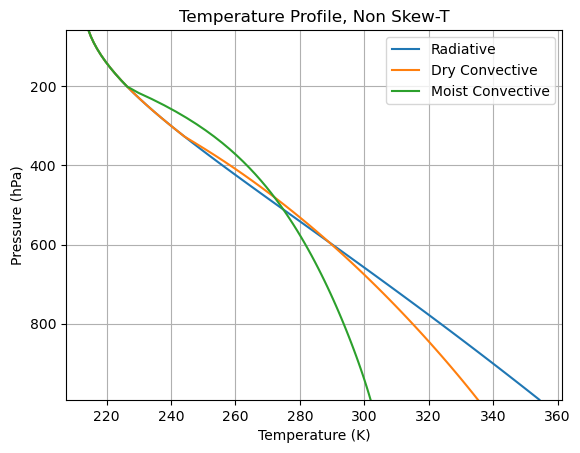

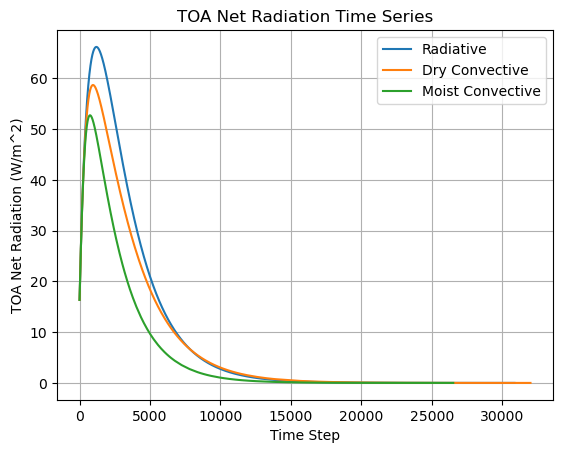

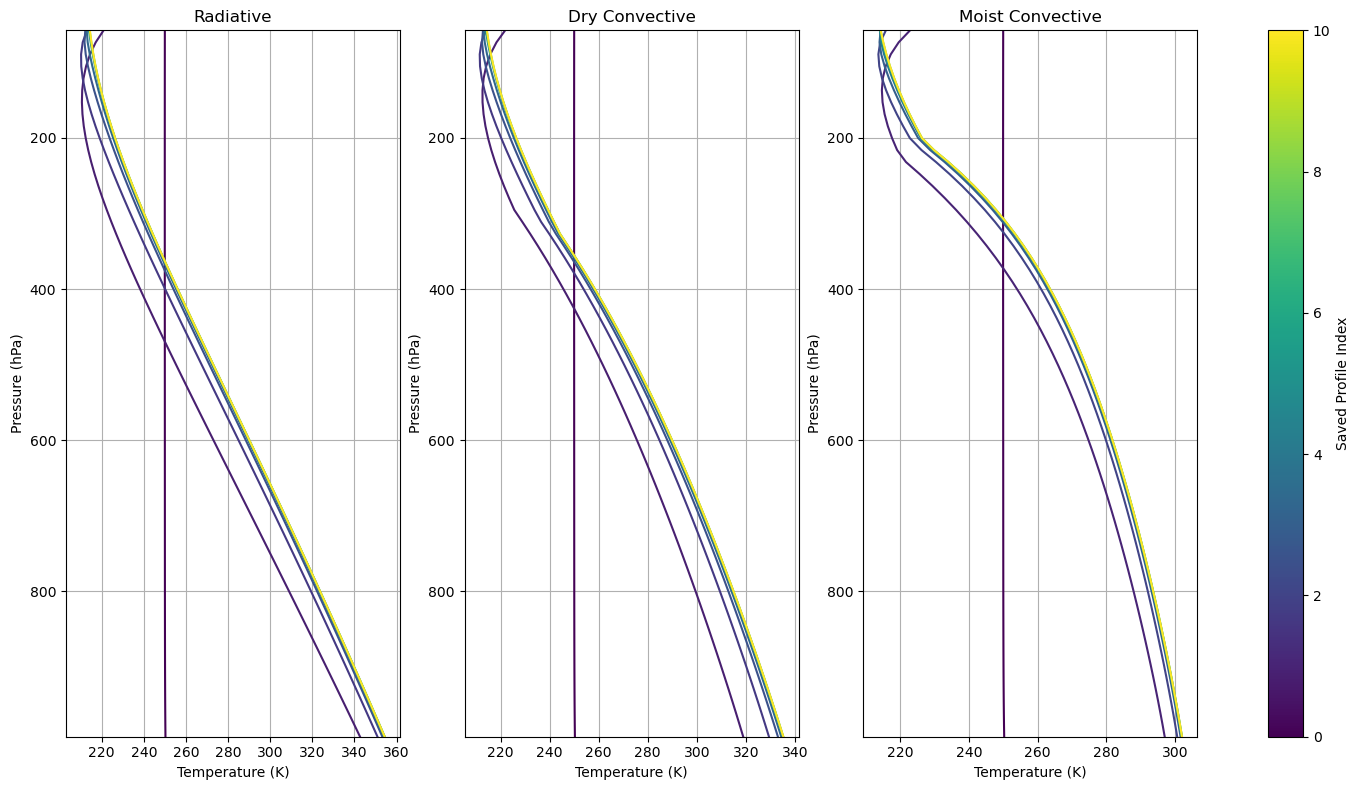

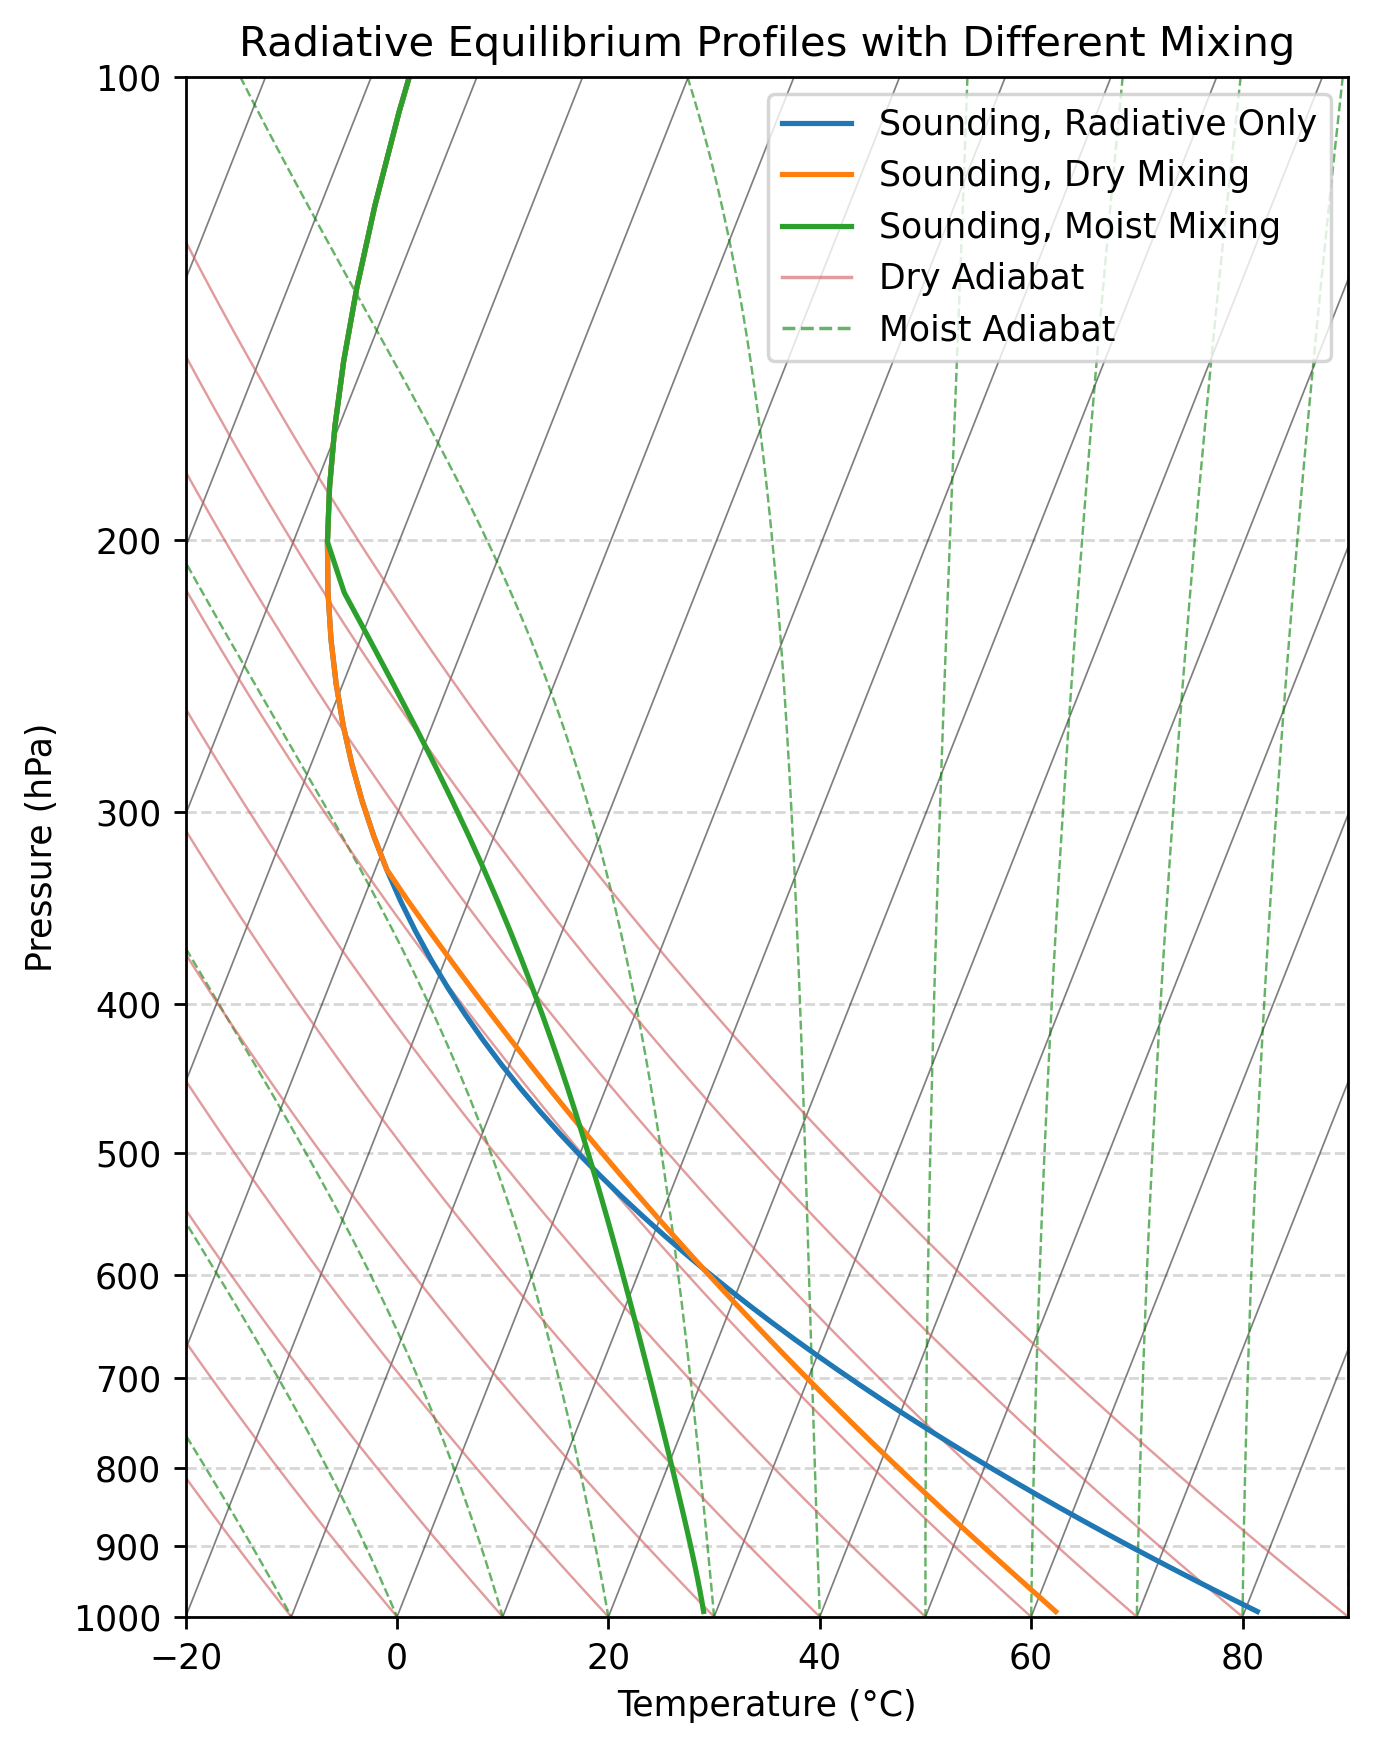

In [50]:
select_experiment = 'convective_mode_variation'
run_everything_i_guess(select_experiment)


Starting RCE run for 'tau0=0.1'
it     0 maxdT=4.43613e-03 K, T_surf=-9.834 C, T0=-23.004 C, OLR=264.27 W/m2, TOA_net=-26.10 W/m2
it  2500 maxdT=2.76972e-03 K, T_surf=-10.726 C, T0=-31.802 C, OLR=257.57 W/m2, TOA_net=-19.40 W/m2
it  5000 maxdT=1.90954e-03 K, T_surf=-11.326 C, T0=-37.427 C, OLR=253.08 W/m2, TOA_net=-14.91 W/m2
it  7500 maxdT=1.43919e-03 K, T_surf=-11.750 C, T0=-41.170 C, OLR=249.91 W/m2, TOA_net=-11.74 W/m2
it 10000 maxdT=1.14774e-03 K, T_surf=-12.061 C, T0=-43.731 C, OLR=247.59 W/m2, TOA_net=-9.42 W/m2
it 12500 maxdT=9.50982e-04 K, T_surf=-12.295 C, T0=-45.519 C, OLR=245.84 W/m2, TOA_net=-7.67 W/m2
it 15000 maxdT=8.09930e-04 K, T_surf=-12.475 C, T0=-46.789 C, OLR=244.50 W/m2, TOA_net=-6.32 W/m2
it 17500 maxdT=7.04137e-04 K, T_surf=-12.615 C, T0=-47.704 C, OLR=243.45 W/m2, TOA_net=-5.27 W/m2
it 20000 maxdT=6.21979e-04 K, T_surf=-12.726 C, T0=-48.373 C, OLR=242.61 W/m2, TOA_net=-4.44 W/m2
it 22500 maxdT=5.56539e-04 K, T_surf=-12.815 C, T0=-48.866 C, OLR=241.94 W/m2, TOA

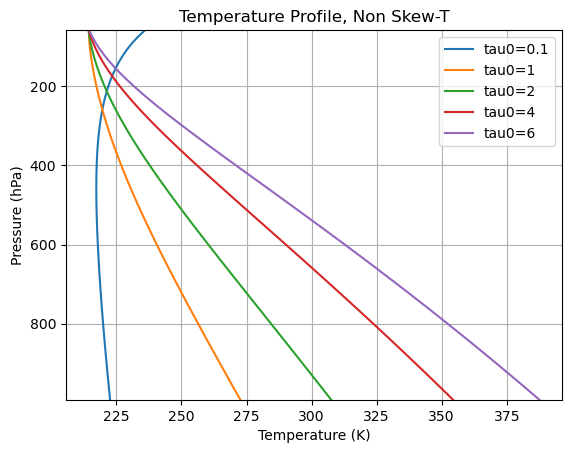

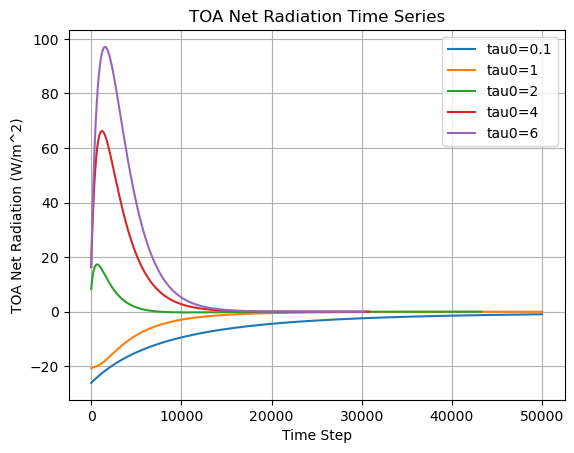

In [51]:
select_experiment = 'tau0_variation'
run_everything_i_guess(select_experiment)

### Not making a Skew-T for the Tau case hehe

## Plots are above, the run in the loops!

## Discussion Questions

### 1. Why do equilibrium profiles differ between the three conditions of mixing: radiative, dry, and moist?

The reason that equilibrium profiles differ between the three profiles is that the dry and moist mixing set maximum allowed lapse rates, while also allowing heat energy to distribute more evenly (than the radiative only case) between the surface and upper levels of the atmosphere. When examining the tau = 4.0 case, the equilibrium temperature profile has a lapse rate larger than dry adiabatic. To see this, observe how the radiative profile crosses from warmer to cooler isentropes on the Skew-T.  

When mixing occurs, the profile is mixed such that it is limited by a maximum lapse rate. The mixing moves energy from the surface to upper levels in the profile. In the code, unstable parcels (where actual lapse is larger than the reference lapse) are assumed to mix half and half with the parcel above them. Further explaination of mixing is provided in question 3. 

This overall makes the top layer warmer and the bottom layer a bit cooler. Throughout the run, this effect is seen throughout the entire profile, where the surface and lowest level temperatures decrease from the radiative, to the dry mixing, to the moist mixing cases. At the same time, the upper levels of the profile are coldest in the radiative case, and warm in the dry mixing and especially the moist mixing cases.

### 2. How does the approach to equilibrium diﬀer among the three equilibrium scenarios, and what is the physical explanation for these diﬀerences?

The approach to equilibrium does not differ too significantly between the three equilibrium scenereos. All three start with a profile of constant temperature with height, and quickly adjust to be warmer at the surface and colder at the upper levels. The difference between the the three profiles really stems from the fact that mixing occurs very quickly. From the beginning of the simulation to the first time step (only 1000 seconds), the dry and moist mixing profiles have already cooled enough that mixing became necesary. Overall, heat is removed from the surface and bottom of the profile and mixed up to the upper levels. Interestingly, all three profiles look the same near the top. This is because the top of the radiative profile never exceeds the dry lapse rate, so no mixing ever occurs.

### 3. Some of the choices you had to make in implementing new components in the model and your process and logic for making those choices.

One of the largest choices that I had to make in this lab was how to physically represent mixing between the two layers. First, let me explain some of my failed attempts at this representation. First, I just simply took the average of the two temperatures between each unstable layer. This did not work and didn't approach equilibrium. Expecting this, I then tried converting the profile to potential temperature and just averaging theta between layers where the temp profile was unstable. Interestingly, this also did not reach a 0 TOA net flux for the dry mixing case. I ended up going back to the temperature profile, and mixing half of the parcel with the parcel above it, with a lapse rate adjustment for the temperature of the mixed half. The half that mixes up cools via the target lapse rate, and the half that mixes down warms via the reference lapse rate. Where layer a is overlayed by layer b, the formulae for the new temps of each layer (in pseudocode) are:

$T_{a1} = (T_{a0} + (T_{b0} + LapseChange))/2$ 
  

$T_{b1} = (T_{b0} + (T_{a0} - LapseChange))/2$  
  
An advantage of this method is that it works for the dry and moist cases. The specified lapse rate just needs to change.